# Análisis de Centralidad Vial

**Contexto:** Una calle fue convertida en vialidad peatonal. Los vecinos argumentan que es la arteria principal de paso vehicular de la zona. Este notebook analiza la red vial circundante con métricas de centralidad de grafos para evaluar ese argumento.

**Métricas sobre aristas (calles):**
- **Betweenness:** cuántos caminos más cortos pasan por la calle — identifica cuellos de botella.
- **Current flow betweenness:** igual que betweenness pero modelando flujo aleatorio, más realista.
- **Closeness (grafo línea):** qué tan cerca está la calle de todas las demás calles.
- **Degree (grafo línea):** con cuántas calles conecta directamente en intersecciones.

**Métricas sobre nodos (intersecciones):**
- **PageRank:** importancia ponderada por la importancia de los vecinos.
- **Closeness:** accesibilidad de la intersección respecto al resto.
- **Degree:** cuántas calles convergen.

**Preprocesamiento de red:**
- Se conserva solo el componente conexo principal.
- Se consolidan intersecciones cercanas (OSM suele mapear una glorieta como 4–5 nodos).


## 1. Importaciones

In [1]:
import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from pyproj import Transformer
import os
import warnings
warnings.filterwarnings('ignore')

print(f'OSMnx: {ox.__version__}')
print(f'NetworkX: {nx.__version__}')

OSMnx: 2.0.7
NetworkX: 3.4.2


## 2. Selección del punto de análisis

Para obtener las coordenadas del punto de interés:

1. Abre **[Google Maps](https://www.google.com/maps/@19.42,-99.13,14z)** (enlace centrado en CDMX)
2. Navega hasta la zona de la vialidad
3. Haz **clic derecho** sobre el punto exacto → aparece el par de coordenadas en la parte superior del menú contextual
4. Haz clic sobre las coordenadas para copiarlas
5. Pégalas en `LATITUD` y `LONGITUD` de la celda siguiente


## 3. Parámetros del análisis

In [2]:
# ─── AJUSTA ESTOS VALORES ────────────────────────────────────────────────────

LATITUD  = 19.37232946200319   # latitud del punto seleccionado
LONGITUD = -99.1583580193611   # longitud

BUFFER_M = 1500                # radio del área de análisis en metros

TIPO_RED = 'drive'             # 'drive' | 'walk' | 'all'

TOLERANCIA_CONSOLIDACION = 15  # metros — fusiona intersecciones a esta distancia

# Betweenness: None = exacto (lento en redes grandes); ej. 300 = aproximado rápido
K_BETWEENNESS = None

# Current flow betweenness es O(n²) — desactivar en redes > ~800 nodos
CALCULAR_CURRENT_FLOW = True

# Grafo línea (closeness/degree por arista) — desactivar si la red es muy grande
CALCULAR_LINEGRAPH = True

# ─────────────────────────────────────────────────────────────────────────────

PUNTO = (LATITUD, LONGITUD)
print(f'Punto         : {PUNTO}')
print(f'Buffer        : {BUFFER_M} m')
print(f'Red           : {TIPO_RED}')
print(f'Consolidación : {TOLERANCIA_CONSOLIDACION} m')

Punto         : (19.37232946200319, -99.1583580193611)
Buffer        : 1500 m
Red           : drive
Consolidación : 15 m


## 4. Descarga y preprocesamiento de la red vial

In [3]:
CACHE_DIR = 'cache'
os.makedirs(CACHE_DIR, exist_ok=True)

raw_id  = f"{LATITUD:.5f}_{LONGITUD:.5f}_{BUFFER_M}m_{TIPO_RED}".replace('-','n').replace('.','p')
proc_id = f"{raw_id}_t{TOLERANCIA_CONSOLIDACION}"
k_tag   = f"k{K_BETWEENNESS}" if K_BETWEENNESS else "kexact"
cent_id = f"{proc_id}_{k_tag}"

GRAFO_RAW_PATH  = f"{CACHE_DIR}/grafo_raw_{raw_id}.graphml"
GRAFO_PROC_PATH = f"{CACHE_DIR}/grafo_proc_{proc_id}.graphml"
ARISTAS_PATH    = f"{CACHE_DIR}/aristas_{cent_id}.gpkg"
NODOS_PATH      = f"{CACHE_DIR}/nodos_{cent_id}.csv"

# 1. Grafo raw
if os.path.exists(GRAFO_RAW_PATH):
    print(f"[caché] Grafo raw: {GRAFO_RAW_PATH}")
    G = ox.load_graphml(GRAFO_RAW_PATH)
else:
    print("Descargando red vial desde OpenStreetMap...")
    G = ox.graph_from_point(PUNTO, dist=BUFFER_M, network_type=TIPO_RED,
                             retain_all=False, simplify=True)
    ox.save_graphml(G, GRAFO_RAW_PATH)
    print(f"Guardado: {GRAFO_RAW_PATH}")

# 2. Grafo preprocesado
if os.path.exists(GRAFO_PROC_PATH):
    print(f"[caché] Grafo preprocesado: {GRAFO_PROC_PATH}")
    G_proj_dir = ox.load_graphml(GRAFO_PROC_PATH)
else:
    print("Preprocesando red...")
    wcc = max(nx.weakly_connected_components(G), key=len)
    G = G.subgraph(wcc).copy()
    print(f"  Componente principal: {len(wcc)} nodos")
    G_proj_dir = ox.project_graph(G, to_crs='EPSG:6372')
    G_proj_dir = ox.consolidate_intersections(
        G_proj_dir, tolerance=TOLERANCIA_CONSOLIDACION,
        rebuild_graph=True, dead_ends=False
    )
    ox.save_graphml(G_proj_dir, GRAFO_PROC_PATH)
    print(f"Guardado: {GRAFO_PROC_PATH}")

# Versión no dirigida + componente conexo principal
G_proj = ox.convert.to_undirected(G_proj_dir)
gcc = max(nx.connected_components(G_proj), key=len)
G_proj = G_proj.subgraph(gcc).copy()

print(f"Nodos : {G_proj.number_of_nodes():,}")
print(f"Aristas: {G_proj.number_of_edges():,}")
print("Red lista")

[caché] Grafo raw: cache/grafo_raw_19p37233_n99p15836_1500m_drive.graphml
[caché] Grafo preprocesado: cache/grafo_proc_19p37233_n99p15836_1500m_drive_t15.graphml
Nodos : 770
Aristas: 1,437
Red lista


## 5. Cálculo de centralidades

> **Betweenness** y **current flow betweenness** pueden tardar varios minutos en redes grandes.
> Ajusta `K_BETWEENNESS` y `CALCULAR_CURRENT_FLOW` en los parámetros si es necesario.


In [4]:
if os.path.exists(ARISTAS_PATH) and os.path.exists(NODOS_PATH):
    print("[caché] Cargando centralidades...")

    df_n = pd.read_csv(NODOS_PATH, index_col='osmid')
    degree_centrality    = df_n['degree'].to_dict()
    closeness_centrality = df_n['closeness'].to_dict()
    pagerank             = df_n['pagerank'].to_dict()

    gdf_e = gpd.read_file(ARISTAS_PATH)
    def _edge_dict(col):
        return {(int(r.u), int(r.v), int(r.key)): r[col] for _, r in gdf_e.iterrows()}
    edge_betweenness  = _edge_dict('betweenness')
    edge_current_flow = _edge_dict('current_flow')
    edge_closeness_lg = _edge_dict('closeness_lg')
    edge_degree_lg    = _edge_dict('degree_lg')

    nodes_gdf, edges_gdf = ox.graph_to_gdfs(G_proj)
    nodes_gdf['degree_centrality']    = nodes_gdf.index.map(degree_centrality)
    nodes_gdf['closeness_centrality'] = nodes_gdf.index.map(closeness_centrality)
    nodes_gdf['pagerank']             = nodes_gdf.index.map(pagerank)

    def _map_edge(d, idx):
        return d.get(idx, d.get((idx[1], idx[0], idx[2]), 0.0))
    edges_gdf['betweenness']  = edges_gdf.index.map(lambda i: _map_edge(edge_betweenness, i))
    edges_gdf['current_flow'] = edges_gdf.index.map(lambda i: _map_edge(edge_current_flow, i))
    edges_gdf['closeness_lg'] = edges_gdf.index.map(lambda i: _map_edge(edge_closeness_lg, i))
    edges_gdf['degree_lg']    = edges_gdf.index.map(lambda i: _map_edge(edge_degree_lg, i))

else:
    # ── Métricas de nodos ────────────────────────────────────────────────────
    print("Calculando degree centrality...")
    degree_centrality = nx.degree_centrality(G_proj)

    print("Calculando closeness centrality...")
    closeness_centrality = nx.closeness_centrality(G_proj, distance='length')

    print("Calculando PageRank (grafo dirigido)...")
    pagerank = nx.pagerank(G_proj_dir, weight='length')

    # ── Betweenness de aristas ───────────────────────────────────────────────
    print(f"Calculando betweenness de aristas (k={K_BETWEENNESS})...")
    edge_betweenness = nx.edge_betweenness_centrality(
        G_proj, weight='length', normalized=True, k=K_BETWEENNESS
    )

    # ── Current flow betweenness ─────────────────────────────────────────────
    if CALCULAR_CURRENT_FLOW:
        n_nodos = G_proj.number_of_nodes()
        if n_nodos > 800:
            print(f"  Aviso: {n_nodos} nodos — current flow puede ser muy lento.")
        print("Calculando current flow betweenness de aristas...")
        # nx.edge_current_flow_betweenness_centrality no admite MultiGraph;
        # se convierte a grafo simple y se mapean los valores de vuelta.
        G_simple = nx.Graph(G_proj)
        _cf_simple = nx.edge_current_flow_betweenness_centrality(
            G_simple, weight='length', normalized=True
        )
        edge_current_flow = {
            (u, v, k): _cf_simple.get((u, v), _cf_simple.get((v, u), 0.0))
            for u, v, k in G_proj.edges(keys=True)
        }
    else:
        print("Current flow betweenness omitido (CALCULAR_CURRENT_FLOW=False).")
        edge_current_flow = {e: 0.0 for e in G_proj.edges(keys=True)}

    # ── Grafo línea ──────────────────────────────────────────────────────────
    if CALCULAR_LINEGRAPH:
        print("Construyendo grafo línea...")
        L = nx.line_graph(G_proj)
        print(f"  Grafo línea: {L.number_of_nodes():,} nodos, {L.number_of_edges():,} aristas")
        print("Calculando closeness en grafo línea...")
        edge_closeness_lg = nx.closeness_centrality(L)
        print("Calculando degree en grafo línea...")
        edge_degree_lg = nx.degree_centrality(L)
    else:
        print("Grafo línea omitido (CALCULAR_LINEGRAPH=False).")
        edge_closeness_lg = {e: 0.0 for e in G_proj.edges(keys=True)}
        edge_degree_lg    = {e: 0.0 for e in G_proj.edges(keys=True)}

    # ── Integrar en GeoDataFrames ────────────────────────────────────────────
    nodes_gdf, edges_gdf = ox.graph_to_gdfs(G_proj)
    nodes_gdf['degree_centrality']    = nodes_gdf.index.map(degree_centrality)
    nodes_gdf['closeness_centrality'] = nodes_gdf.index.map(closeness_centrality)
    nodes_gdf['pagerank']             = nodes_gdf.index.map(pagerank)

    def _map_edge(d, idx):
        return d.get(idx, d.get((idx[1], idx[0], idx[2]), 0.0))
    edges_gdf['betweenness']  = edges_gdf.index.map(lambda i: _map_edge(edge_betweenness, i))
    edges_gdf['current_flow'] = edges_gdf.index.map(lambda i: _map_edge(edge_current_flow, i))
    edges_gdf['closeness_lg'] = edges_gdf.index.map(lambda i: _map_edge(edge_closeness_lg, i))
    edges_gdf['degree_lg']    = edges_gdf.index.map(lambda i: _map_edge(edge_degree_lg, i))

    # ── Guardar caché ────────────────────────────────────────────────────────
    pd.DataFrame({
        'osmid':     list(degree_centrality.keys()),
        'degree':    [degree_centrality[n]    for n in degree_centrality],
        'closeness': [closeness_centrality[n] for n in degree_centrality],
        'pagerank':  [pagerank.get(n, 0.0)    for n in degree_centrality],
    }).set_index('osmid').to_csv(NODOS_PATH)

    aristas_cache = edges_gdf[[
        'geometry','name','highway','length',
        'betweenness','current_flow','closeness_lg','degree_lg'
    ]].reset_index()
    aristas_cache.to_file(ARISTAS_PATH, driver='GPKG')
    print(f"Caché guardado en: {CACHE_DIR}/")

for col in ['betweenness','current_flow','closeness_lg','degree_lg']:
    p90 = edges_gdf[col].quantile(0.90)
    print(f"  {col:15s} p90={p90:.4f}")
print("Centralidades listas")

[caché] Cargando centralidades...
  betweenness     p90=0.0311
  current_flow    p90=0.0000
  closeness_lg    p90=0.0836
  degree_lg       p90=0.0070
Centralidades listas


In [5]:
transformer = Transformer.from_crs('EPSG:4326', 'EPSG:6372', always_xy=True)
px, py = transformer.transform(LONGITUD, LATITUD)

nodo_ref, dist_ref = ox.distance.nearest_nodes(G_proj, X=px, Y=py, return_dist=True)
print(f"Punto proyectado  : ({px:.1f}, {py:.1f})")
print(f"Nodo de referencia: {nodo_ref}  (a {dist_ref:.1f} m del punto)")

def edge_vals_for(metric_dict):
    return [
        metric_dict.get(e, metric_dict.get((e[1], e[0], e[2]), 0.0))
        for e in G_proj.edges(keys=True)
    ]

vals_betweenness  = edge_vals_for(edge_betweenness)
vals_current_flow = edge_vals_for(edge_current_flow)
vals_closeness_lg = edge_vals_for(edge_closeness_lg)
vals_degree_lg    = edge_vals_for(edge_degree_lg)

Punto proyectado  : (2797661.3, 822353.9)
Nodo de referencia: 352  (a 163.4 m del punto)


## 6. Betweenness — calles de mayor paso

**¿Qué mide?** El porcentaje de caminos más cortos entre todos los pares de nodos de la red que pasan por cada calle. Una calle con alta betweenness es un **cuello de botella**: si se cierra, muchos viajes deben dar un rodeo considerable.

**Interpretación:** Las calles rojas/brillantes son las que más tráfico potencial concentran según la topología de la red. Si la vialidad en cuestión aparece destacada aquí, el argumento vecinal tiene peso estructural.

**Limitación:** Asume que todo el mundo toma el camino más corto. En la práctica, el tráfico se distribuye más difusamente.

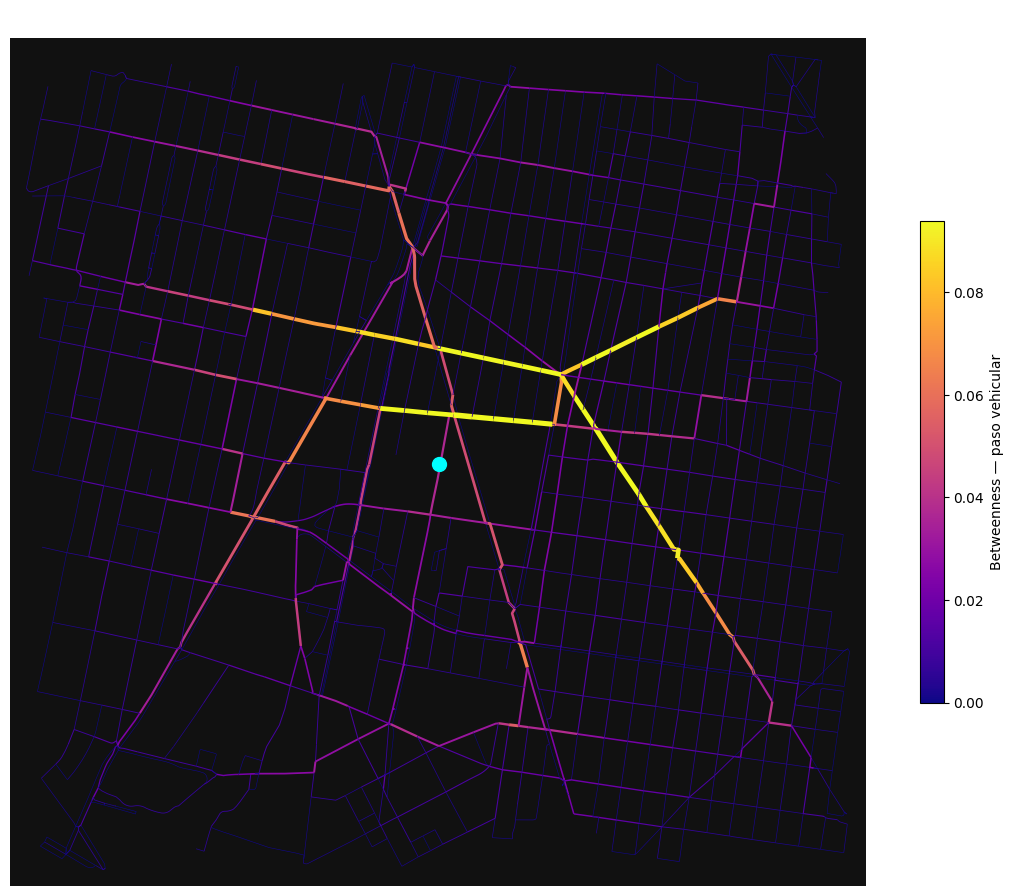

In [6]:
def plot_edge_metric(G, edge_vals, titulo, cmap_name='plasma',
                     bgcolor='#111111', title_color='white', figsize=(11, 11)):
    vmin   = min(edge_vals)
    vmax   = np.quantile(edge_vals, 0.99)
    norm   = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap   = cm.get_cmap(cmap_name)
    colors = [cmap(norm(v)) for v in edge_vals]
    widths = [0.4 + 3.0 * norm(v) for v in edge_vals]

    fig, ax = ox.plot_graph(G, edge_color=colors, edge_linewidth=widths,
                             node_size=0, bgcolor=bgcolor,
                             show=False, close=False, figsize=figsize)
    ax.scatter(px, py, c='cyan', s=100, zorder=6)
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(sm, ax=ax, shrink=0.45, label=titulo)
    ax.set_title(titulo, color=title_color, pad=10, fontsize=13)
    plt.tight_layout()
    plt.show()


def plot_node_metric(G, metric_dict, titulo, cmap_name='YlOrRd',
                     bgcolor='white', figsize=(11, 11)):
    node_vals = [metric_dict.get(n, 0.0) for n in G.nodes()]
    vmin   = min(node_vals)
    vmax   = np.quantile(node_vals, 0.99)
    norm   = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap   = cm.get_cmap(cmap_name)
    colors = [cmap(norm(v)) for v in node_vals]
    sizes  = [2 + 12 * norm(v) for v in node_vals]

    fig, ax = ox.plot_graph(G, node_color=colors, node_size=sizes,
                             edge_color='#dddddd', edge_linewidth=0.3,
                             bgcolor=bgcolor, show=False, close=False, figsize=figsize)
    ax.scatter(px, py, c='blue', s=100, zorder=6, marker='*')
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(sm, ax=ax, shrink=0.45, label=titulo)
    ax.set_title(titulo, pad=10, fontsize=13)
    plt.tight_layout()
    plt.show()


plot_edge_metric(G_proj, vals_betweenness, 'Betweenness — paso vehicular')

## 7. Current flow betweenness — flujo realista

**¿Qué mide?** Similar a betweenness, pero en lugar de contar solo el camino mínimo, modela el tráfico como un flujo eléctrico que se distribuye por **todos los caminos posibles** con probabilidades inversamente proporcionales a su longitud. Captura calles que absorben flujo aunque no sean la ruta más corta.

**Interpretación:** Complementa a betweenness clásico. Una calle que sale alta en ambas métricas tiene una centralidad muy robusta. Si aparece alta aquí pero no en betweenness (o viceversa), su rol depende del patrón de viaje asumido.

**Nota técnica:** Este cálculo es O(n²) — puede ser lento en redes con más de ~800 nodos. Se puede desactivar con `CALCULAR_CURRENT_FLOW = False`.

In [7]:
if CALCULAR_CURRENT_FLOW and any(v > 0 for v in vals_current_flow):
    plot_edge_metric(G_proj, vals_current_flow,
                     'Current flow betweenness — flujo realista', cmap_name='inferno')
else:
    print("Current flow betweenness no calculado (CALCULAR_CURRENT_FLOW=False).")

Current flow betweenness no calculado (CALCULAR_CURRENT_FLOW=False).


## 8. Closeness por arista (grafo línea)

**¿Qué mide?** Se construye un **grafo línea**: cada calle se convierte en un nodo y dos calles se conectan si comparten una intersección. Luego se calcula closeness sobre ese grafo: qué tan cerca está cada calle de todas las demás calles de la zona, medido en número de intersecciones que hay que cruzar.

**Interpretación:** Alta closeness = calle bien ubicada en la red de calles, desde la que se puede llegar a cualquier otra calle en pocos giros. Identifica calles **estructuralmente céntricas** más allá del volumen de tráfico que concentran.

**Diferencia con closeness nodal:** Aquí la unidad es la calle, no la intersección. Útil para evaluar la posición de un segmento vial dentro de la trama urbana.

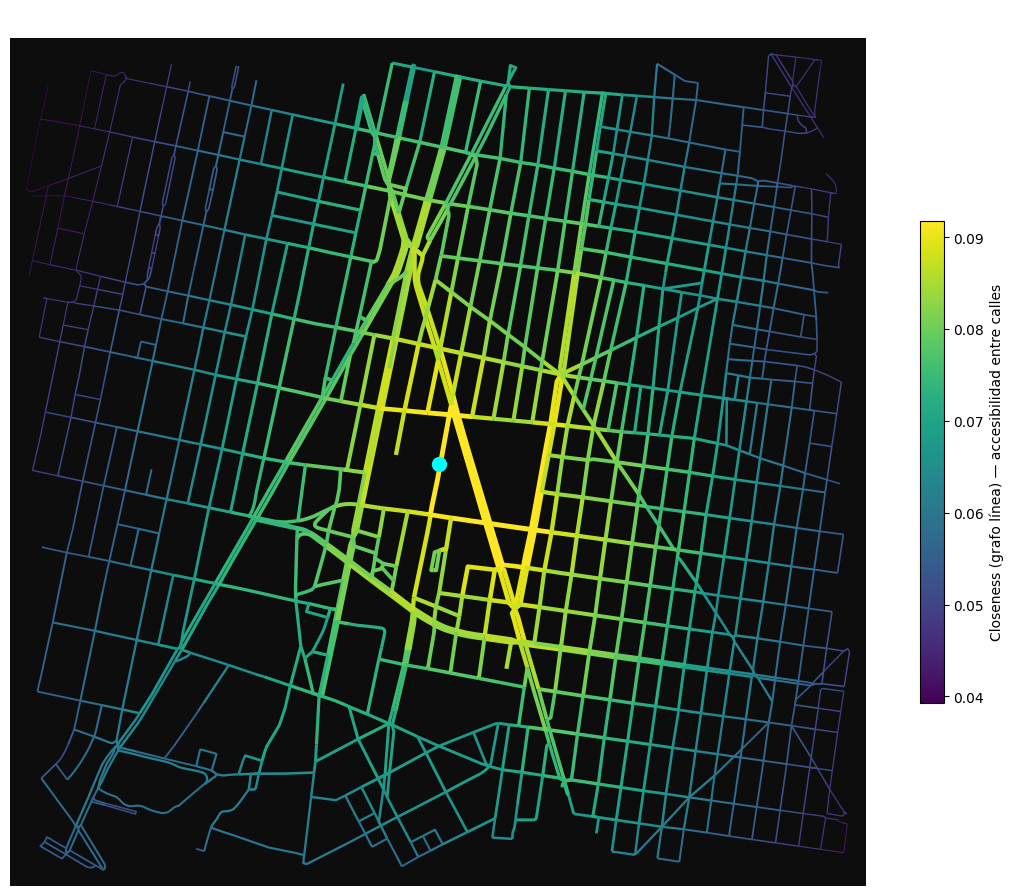

In [8]:
if CALCULAR_LINEGRAPH and any(v > 0 for v in vals_closeness_lg):
    plot_edge_metric(G_proj, vals_closeness_lg,
                     'Closeness (grafo línea) — accesibilidad entre calles',
                     cmap_name='viridis', bgcolor='#0d0d0d')
else:
    print("Grafo línea no calculado (CALCULAR_LINEGRAPH=False).")

## 9. Degree por arista (grafo línea) — conectividad entre calles

**¿Qué mide?** En el grafo línea, el degree de cada calle equivale al número de otras calles con las que conecta directamente en sus extremos. Una calle con degree alto toca muchas otras calles en sus intersecciones.

**Interpretación:** Alta conectividad = calle que articula muchos segmentos distintos. Es una medida de **multiplicidad de conexiones**: no qué tan lejos llega, sino cuántas opciones de giro ofrece a quienes la transitan.

**Uso conjunto:** Combinada con betweenness y closeness, permite distinguir entre calles que son importantes por su posición (closeness), por el tráfico que concentran (betweenness) o por la variedad de conexiones que ofrecen (degree).

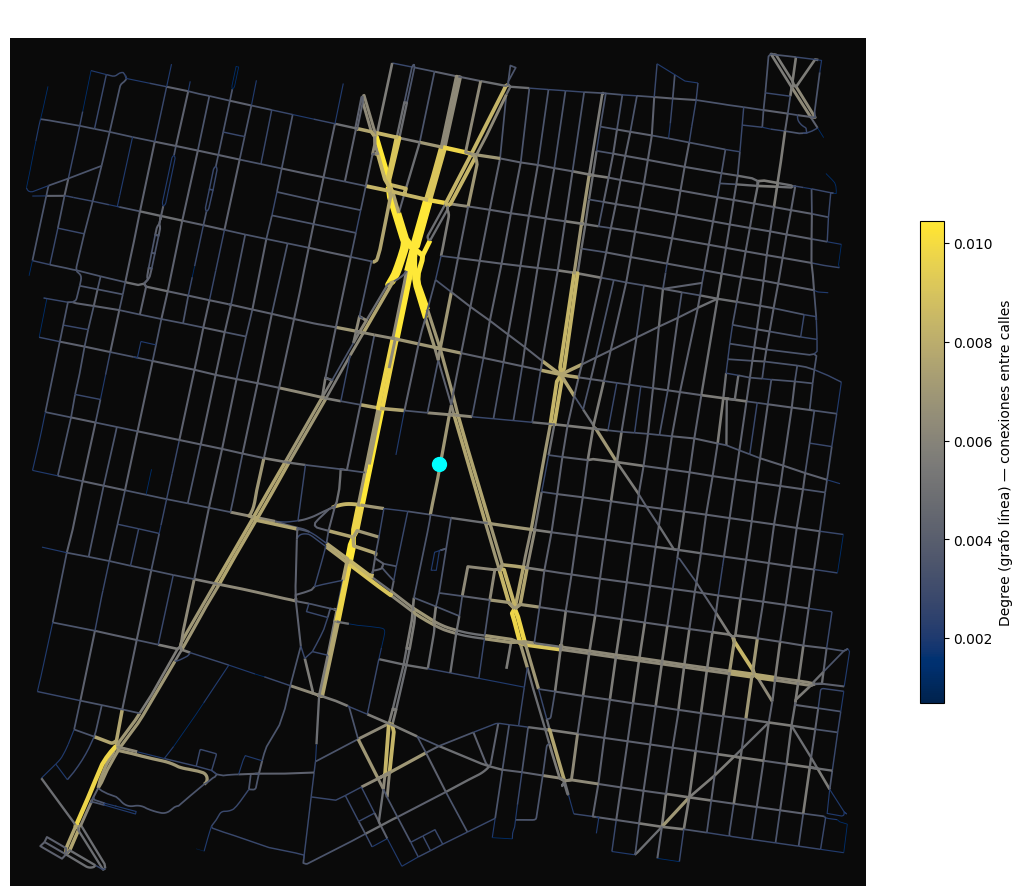

In [9]:
if CALCULAR_LINEGRAPH and any(v > 0 for v in vals_degree_lg):
    plot_edge_metric(G_proj, vals_degree_lg,
                     'Degree (grafo línea) — conexiones entre calles',
                     cmap_name='cividis', bgcolor='#0a0a0a')
else:
    print("Grafo línea no calculado (CALCULAR_LINEGRAPH=False).")

## 10. PageRank — jerarquía de intersecciones

**¿Qué mide?** Adapta el algoritmo de Google al grafo vial dirigido, ponderado por longitud de calle. Una intersección tiene alto PageRank si está conectada a otras intersecciones también importantes. A diferencia de degree, no basta con tener muchas conexiones: importa la calidad de esas conexiones.

**Interpretación:** Identifica los **nodos clave** de la jerarquía vial. Una intersección con alto PageRank es un punto de confluencia de calles relevantes — el tipo de cruce que, si se cierra, afecta toda la zona.

**Dirección:** Se calcula sobre el grafo dirigido (sentidos de circulación de OSM), lo que lo hace más fiel a la realidad del tráfico vehicular.

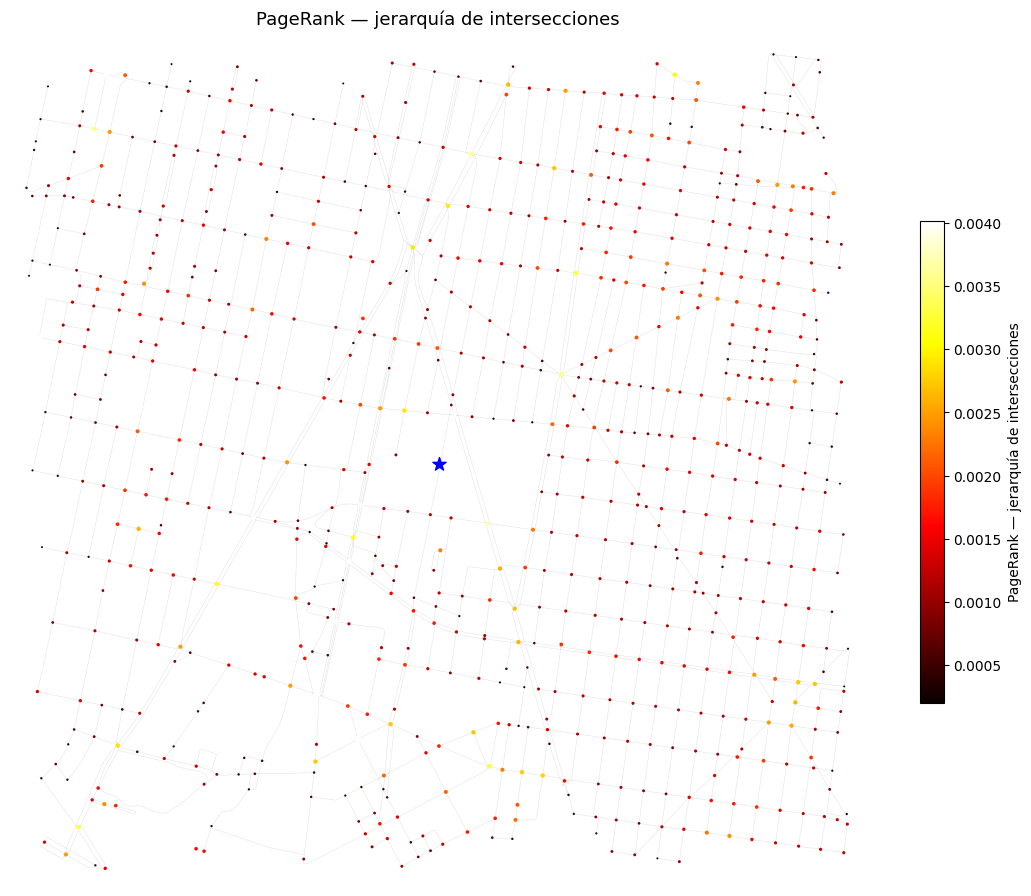

In [10]:
plot_node_metric(G_proj, pagerank,
                 'PageRank — jerarquía de intersecciones', 'hot')

## 11. Closeness y Degree nodales

**Closeness nodal — ¿qué mide?** Qué tan rápido puede una intersección alcanzar todas las demás de la red, medido como el inverso de la suma de distancias (en metros) a todos los nodos. Alta closeness = intersección bien ubicada geográficamente en el conjunto de la red.

**Diferencia con PageRank:** Closeness es puramente geométrico (distancias métricas); PageRank es topológico y pondera la importancia de los vecinos. Una intersección periférica puede tener bajo closeness pero alto PageRank si conecta con arterias relevantes.

**Degree nodal — ¿qué mide?** El número de calles que confluyen en cada intersección, normalizado por el total de nodos. Es la medida más simple de conectividad local: un cruce con degree alto es un **nodo de transferencia** donde convergen múltiples opciones de circulación.

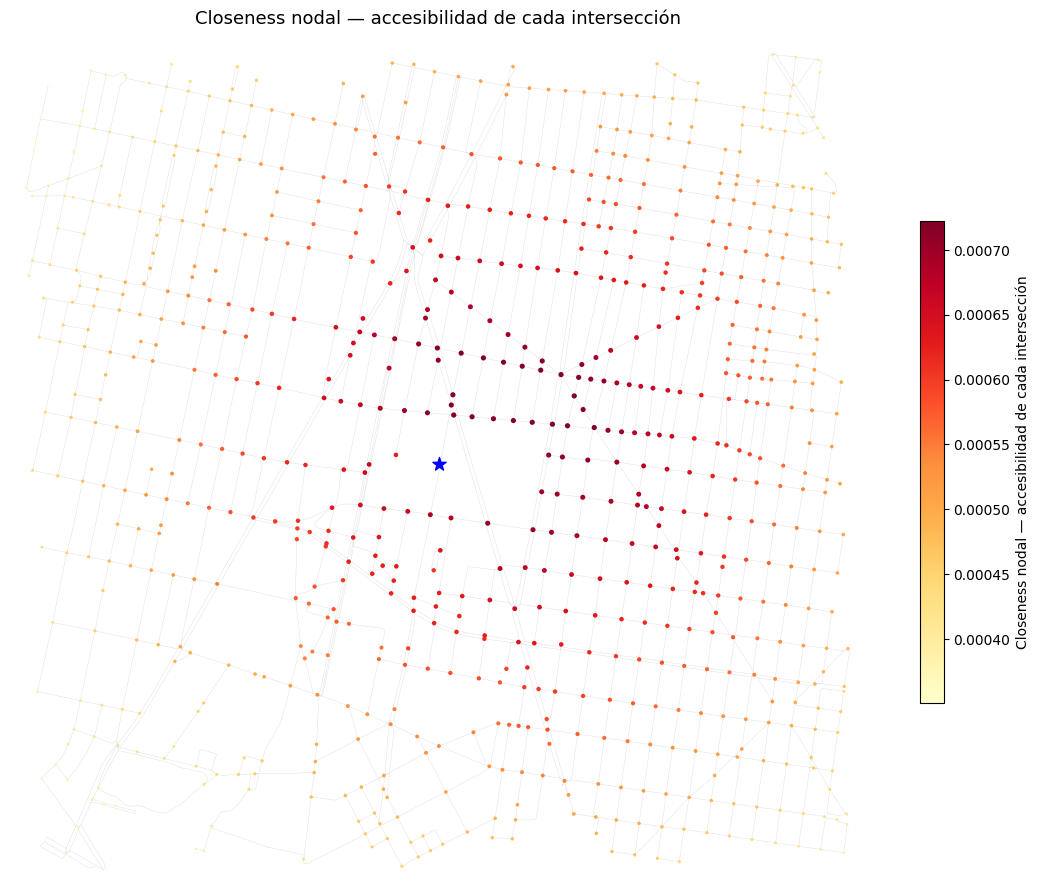

In [11]:
plot_node_metric(G_proj, closeness_centrality,
                 'Closeness nodal — accesibilidad de cada intersección', 'YlOrRd')

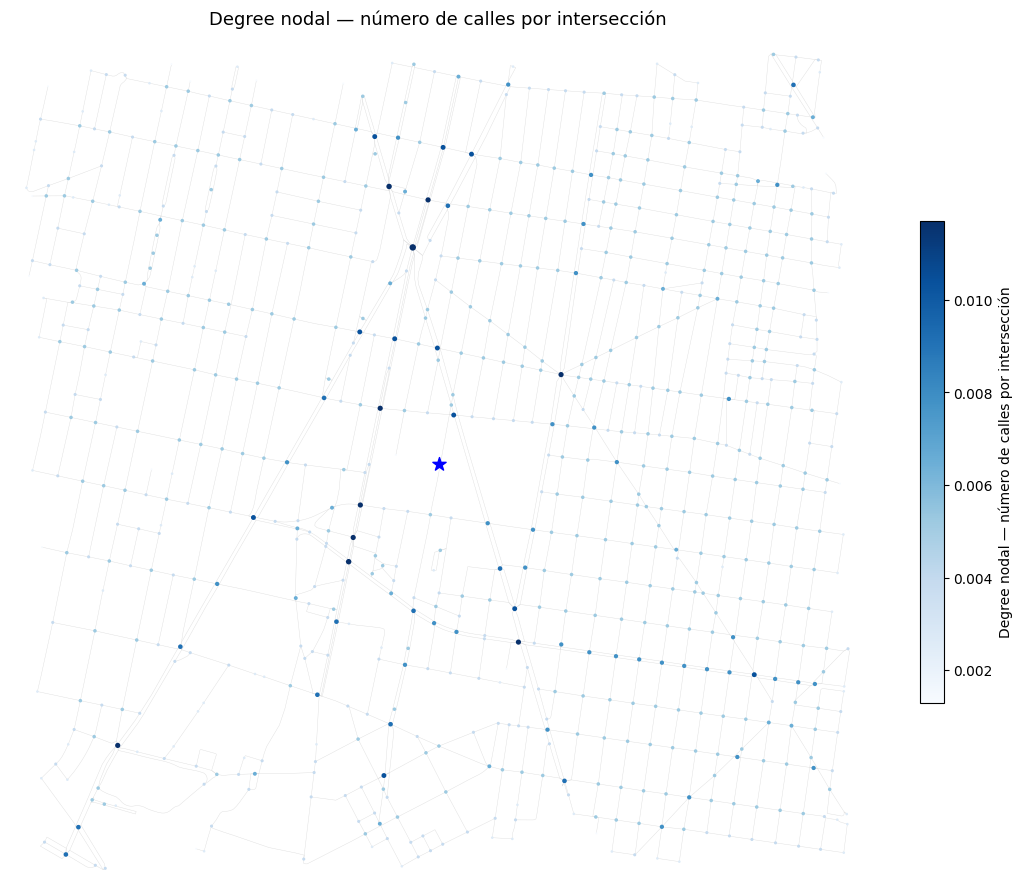

In [12]:
plot_node_metric(G_proj, degree_centrality,
                 'Degree nodal — número de calles por intersección', 'Blues')

## 12. Ranking de calles por métrica

Agrega las métricas de arista por nombre de calle (tomando el valor máximo de todos los segmentos con ese nombre) y ordena de mayor a menor betweenness. Permite identificar de un vistazo **cuáles son las calles más relevantes de la zona** según cada criterio, y comparar si la vialidad analizada aparece consistentemente entre las primeras posiciones.

In [13]:
cols_metrica = ['betweenness', 'current_flow', 'closeness_lg', 'degree_lg']
cols_activos = [c for c in cols_metrica if edges_gdf[c].sum() > 0]

def normalizar_nombre(x):
    if isinstance(x, list):
        return ' / '.join(str(n) for n in x if n)
    return x

ranking = (
    edges_gdf[['name'] + cols_activos]
    .reset_index(drop=True)
    .assign(name=lambda df: df['name'].map(normalizar_nombre).fillna('Sin nombre'))
    .groupby('name')[cols_activos].max()
    .reset_index()
    .sort_values('betweenness', ascending=False)
    .head(25)
    .reset_index(drop=True)
)
ranking.index += 1
ranking.index.name = 'rango'

ranking.style.background_gradient(subset=cols_activos, cmap='YlOrRd')

,name,betweenness,closeness_lg,degree_lg
rango,,,,
1,Calle Miguel Laurent,0.112766,0.093429,0.007660
2,Calle Bulgaria,0.101967,0.085056,0.008357
3,Calle Cuicuilco,0.096043,0.084725,0.007660
4,Calle Pilares,0.094196,0.087173,0.007660
5,Avenida Lázaro Cárdenas,0.091493,0.076148,0.005571
6,Avenida Doctor José María Vértiz,0.067961,0.093654,0.008357
7,Calle Luis Spota,0.065972,0.065285,0.004875
8,Avenida Universidad,0.065759,0.084955,0.011142
9,Avenida División del Norte,0.063824,0.096344,0.015320


## 13. Análisis del punto de referencia

In [14]:
print(f"Nodo de referencia: {nodo_ref}  (a {dist_ref:.1f} m del punto)\n")

print("Métricas nodales:")
for col, lbl in [('degree_centrality','Degree'), ('closeness_centrality','Closeness'), ('pagerank','PageRank')]:
    val = nodes_gdf.loc[nodo_ref, col] if nodo_ref in nodes_gdf.index else float('nan')
    serie = nodes_gdf[col].dropna()
    pct = (serie < val).mean() * 100
    print(f"  {lbl:12s}: {val:.6f}  (percentil {pct:.1f}%)")

print("\nAristas conectadas al nodo de referencia:")
adj = edges_gdf.loc[
    [(u, v, k) for u, v, k in edges_gdf.index if u == nodo_ref or v == nodo_ref],
    ['name', 'betweenness', 'current_flow', 'closeness_lg', 'degree_lg']
]
if not adj.empty:
    print(adj.to_string())
else:
    print("  (ninguna encontrada con ese nodo)")

Nodo de referencia: 352  (a 163.4 m del punto)

Métricas nodales:
  Degree      : 0.001300  (percentil 0.0%)
  Closeness   : 0.000626  (percentil 81.0%)
  PageRank    : 0.001016  (percentil 32.1%)

Aristas conectadas al nodo de referencia:
                         name  betweenness  current_flow  closeness_lg  degree_lg
u   v   key                                                                      
350 352 0    Cerrada Tenayuca     0.002597           0.0      0.086778   0.002089


## 14. Mapa resumen — top 10% por métrica

Resalta en rojo las calles que pertenecen al **decil superior** de cada métrica. Útil para comparar visualmente qué calles son importantes según distintos criterios: si la misma calle aparece roja en todos los mapas, su centralidad es robusta e independiente del método de medición.

El punto naranja marca el lugar de análisis ingresado.

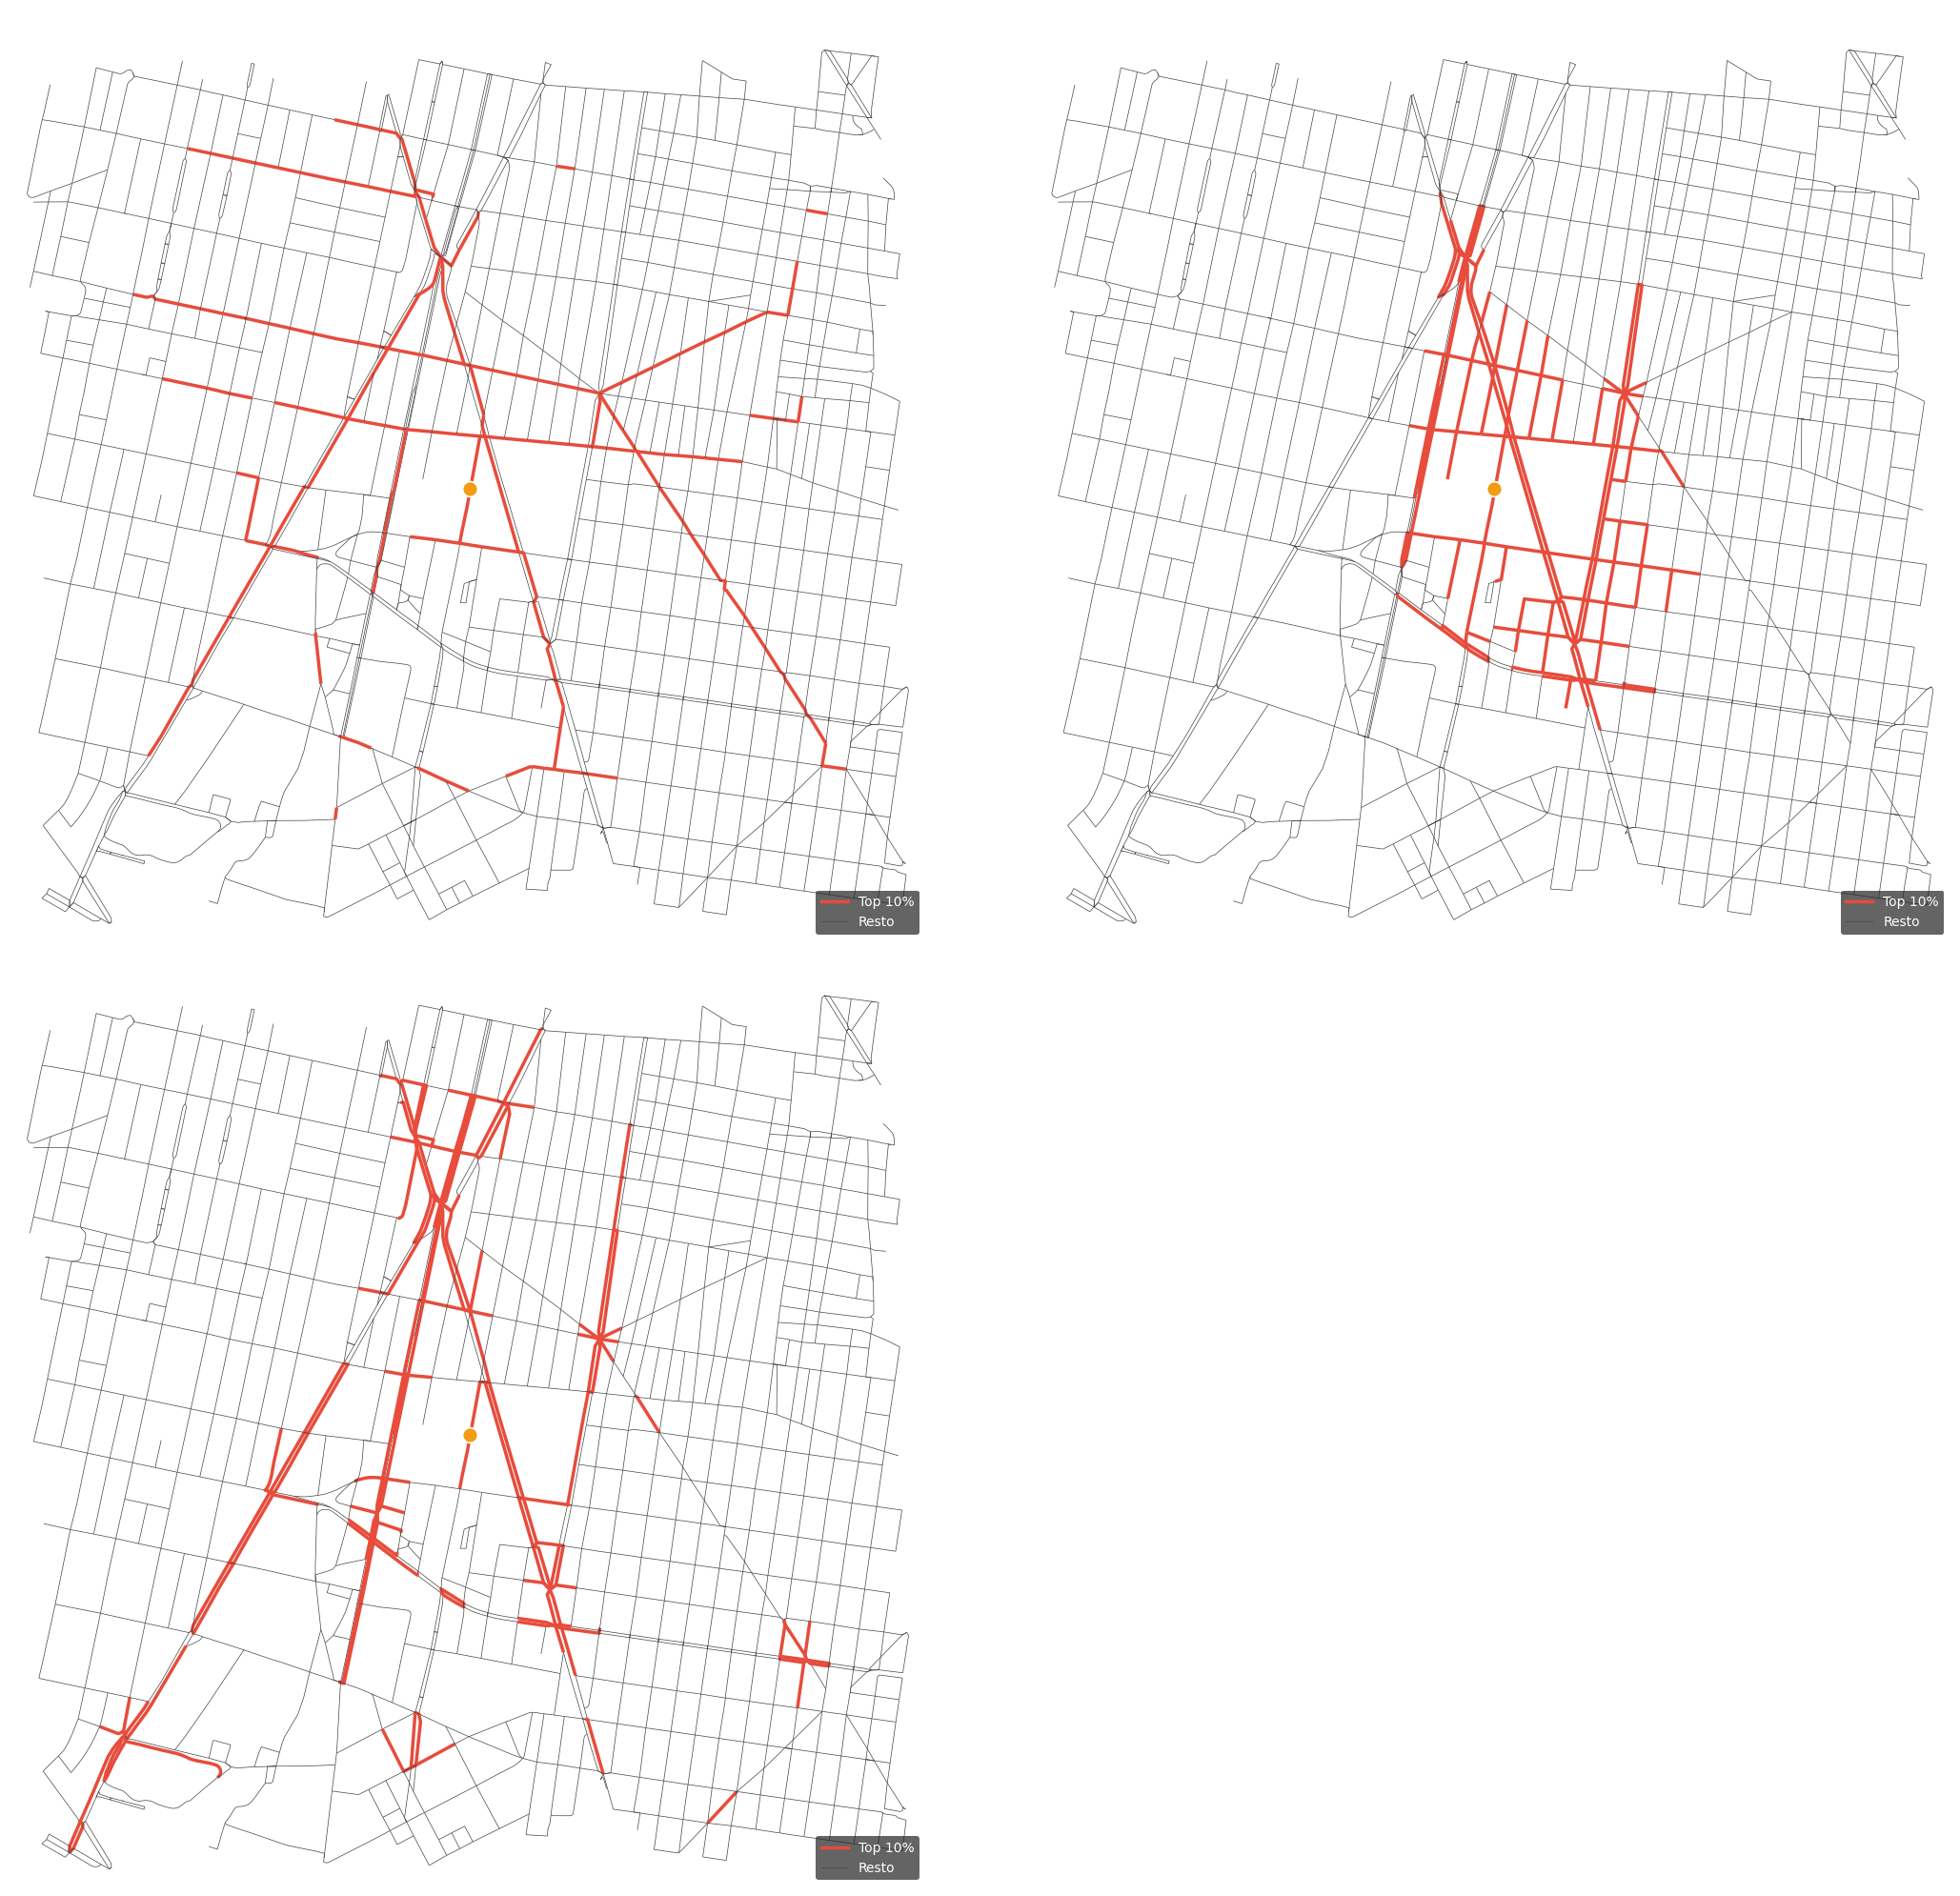

In [15]:
pares = [
    (vals_betweenness,  'Betweenness'),
    (vals_current_flow, 'Current flow betw.'),
    (vals_closeness_lg, 'Closeness (línea)'),
    (vals_degree_lg,    'Degree (línea)'),
]
pares_activos = [(v, t) for v, t in pares if any(x > 0 for x in v)]

if not pares_activos:
    print("No hay métricas calculadas para graficar.")
else:
    n_cols = min(2, len(pares_activos))
    n_rows = (len(pares_activos) + 1) // 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(11 * n_cols, 10 * n_rows))
    axes = np.array(axes).flatten()

    for ax, (vals, titulo) in zip(axes, pares_activos):
        p90_v  = np.quantile(vals, 0.90)
        colors = ['#e74c3c' if v >= p90_v else '#444444' for v in vals]
        widths = [2.5      if v >= p90_v else 0.5       for v in vals]
        ox.plot_graph(G_proj, edge_color=colors, edge_linewidth=widths,
                      node_size=0, bgcolor='#111111', ax=ax, show=False, close=False)
        ax.scatter(px, py, c='#f39c12', s=130, zorder=6,
                   edgecolors='white', linewidths=1.2)
        ax.set_title(f'{titulo} — top 10%', color='white', fontsize=11, pad=8)
        ax.legend(handles=[
            Line2D([0],[0], color='#e74c3c', lw=2.5, label='Top 10%'),
            Line2D([0],[0], color='#444444', lw=0.5, label='Resto'),
        ], loc='lower right', framealpha=0.7, labelcolor='white',
           facecolor='#222222', edgecolor='none')

    for ax in axes[len(pares_activos):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

## 15. Exportar resultados

In [17]:
edges_gdf.head(1)

,,,osmid,highway,lanes,name,oneway,reversed,length,u_original,v_original,geometry,...,to,maxspeed,ref,tunnel,access,width,betweenness,current_flow,closeness_lg,degree_lg
u,v,key,,,,,,,,,,,,,,,,,,,,,
0,1,0,396108080,residential,4,Calle Matías Romero,False,True,93.753504,275512749,30339671,"LINESTRING (2798254.883 823037.61, 2798168.999...",...,0,NaN,NaN,NaN,NaN,NaN,0.014564,0.0,0.081116,0.005571


In [16]:
output_dir = 'datos/centralidad'
os.makedirs(output_dir, exist_ok=True)

cols_a = [c for c in ['name','highway','length','betweenness','current_flow',
                       'closeness_lg','degree_lg','geometry'] if c in edges_gdf.columns]
cols_n = [c for c in ['degree_centrality','closeness_centrality','pagerank','geometry']
          if c in nodes_gdf.columns]

edges_gdf[cols_a].to_crs('EPSG:4326').to_file(f'{output_dir}/aristas_centralidad.gpkg', driver='GPKG')
nodes_gdf[cols_n].to_crs('EPSG:4326').to_file(f'{output_dir}/nodos_centralidad.gpkg',  driver='GPKG')

print(f"Exportado en: {output_dir}/")
print("  aristas_centralidad.gpkg — betweenness, current_flow, closeness_lg, degree_lg")
print("  nodos_centralidad.gpkg   — degree, closeness, pagerank")

Exportado en: datos/centralidad/
  aristas_centralidad.gpkg — betweenness, current_flow, closeness_lg, degree_lg
  nodos_centralidad.gpkg   — degree, closeness, pagerank
